In [2]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from scipy import stats
pd.set_option('display.float_format', lambda x: '%.3f' % x)

In [3]:
df = pd.read_csv("../../data/counters.csv", index_col=0, parse_dates=["datetime"], date_format={"datetime": "ISO8601"})
print(df.shape)
df.head()

(4634800, 8)


,location_index,channels_in,channels_out,channels_unknown,channels_all,site_temperature,site_rain_accumulation,datetime
0,0,4.000,1.000,NaN,5,0.000,0.000,2020-12-31 23:00:00+00:00
1,0,2.000,0.000,NaN,2,0.000,0.000,2021-01-01 00:00:00+00:00
2,0,1.000,0.000,NaN,1,0.000,0.000,2021-01-01 01:00:00+00:00
3,0,2.000,0.000,NaN,2,0.000,0.000,2021-01-01 02:00:00+00:00
4,0,0.000,0.000,NaN,0,0.000,0.000,2021-01-01 03:00:00+00:00


In [4]:
# What's up with the channels_unknown feature?
mask_unknown = df.channels_unknown.notna()
df.loc[mask_unknown, :].head()

,location_index,channels_in,channels_out,channels_unknown,channels_all,site_temperature,site_rain_accumulation,datetime
147431,3,NaN,NaN,7.000,7,2.000,0.100,2020-12-31 23:00:00+00:00
147432,3,NaN,NaN,2.000,2,2.000,0.200,2021-01-01 00:00:00+00:00
147433,3,NaN,NaN,2.000,2,2.000,0.200,2021-01-01 01:00:00+00:00
147434,3,NaN,NaN,5.000,5,2.000,0.300,2021-01-01 02:00:00+00:00
147435,3,NaN,NaN,6.000,6,2.000,0.300,2021-01-01 03:00:00+00:00


In [5]:
either_mask = (df.channels_unknown.isna() | (df.channels_in.isna() & df.channels_out.isna()))
df.loc[~either_mask, :].head()

,location_index,channels_in,channels_out,channels_unknown,channels_all,site_temperature,site_rain_accumulation,datetime
2372547,50,20.000,23.000,0.000,43,9.000,0.000,2025-03-27 09:00:00+00:00


In [6]:
(df.channels_in.fillna(0) + df.channels_out.fillna(0) + df.channels_unknown.fillna(0) == df.channels_all).all()#
# It seems like channels_all counts all passengers, in and out count different directions wherever known

np.True_

In [7]:
df = df.drop(columns=["channels_in", "channels_out", "channels_unknown"])

In [8]:
df.describe() # Is site_accumulation realistic? The other ones look fine

,location_index,channels_all,site_temperature,site_rain_accumulation
count,4634800.000,4634800.000,4568232.000,4568232.000
mean,48.439,65.729,11.156,0.099
std,28.179,125.141,7.947,0.435
min,0.000,0.000,-18.000,0.000
25%,24.000,4.000,5.000,0.000
50%,49.000,20.000,11.000,0.000
75%,73.000,66.000,17.000,0.000
max,104.000,9002.000,42.000,30.400


(-20.0, 657.0)

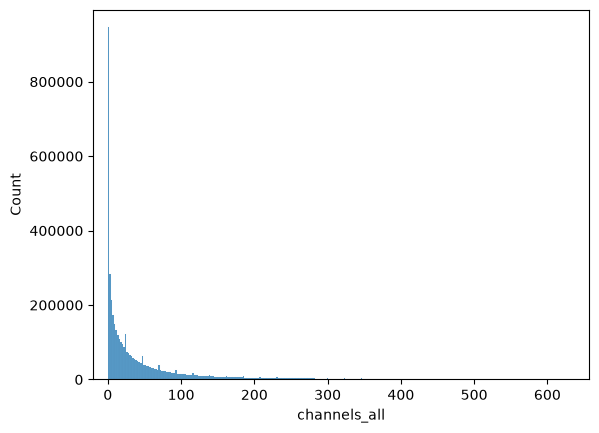

In [9]:
fig, ax = plt.subplots()
sns.histplot(df.channels_all, ax=ax)
ax.set_xlim(-20, df.channels_all.quantile(0.99)) # channel_all looks Poisson distributed, which makes sense

<Axes: xlabel='site_temperature', ylabel='Count'>

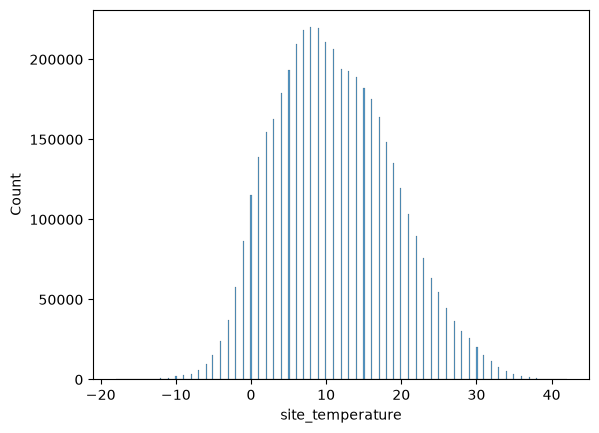

In [10]:
fig, ax = plt.subplots()
sns.histplot(df.site_temperature, ax=ax)

(-20.0, 657.0)

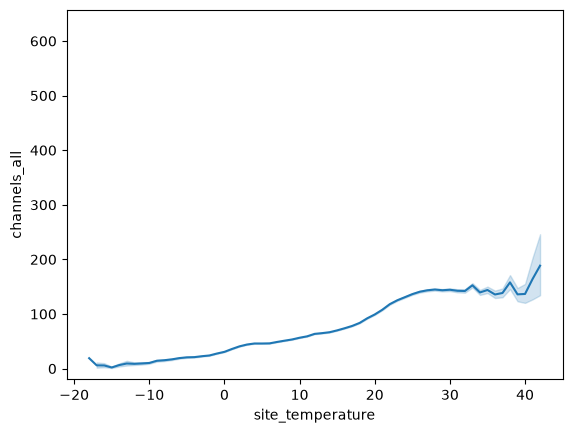

In [11]:
fig, ax = plt.subplots()
sns.lineplot(data=df, x="site_temperature", y="channels_all", ax=ax)
ax.set_ylim(-20, df.channels_all.quantile(0.99))

In [12]:
# It seems like all sites have at least a bit of rain, so maybe they are accurate after all
df.site_rain_accumulation.groupby(by=df.location_index).max().min()


np.float64(5.7)

In [13]:
dist = stats.poisson(df.channels_all.mean())

<Axes: xlabel='datetime', ylabel='channels_all'>

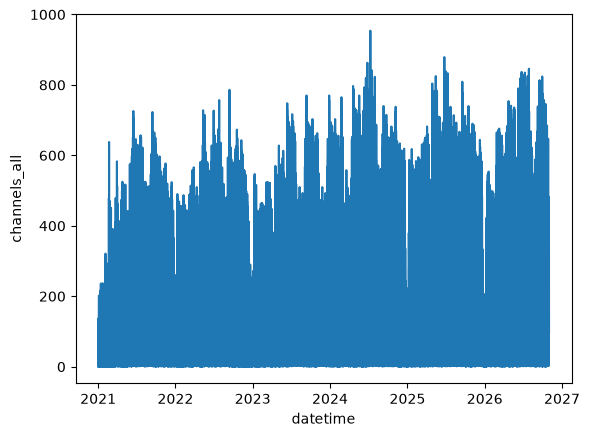

In [14]:
sns.lineplot(data=df.loc[df.location_index == 0, :], x="datetime", y="channels_all")

/var/folders/32/vygvwqrx4qx5g6w9q4y9ct180000gn/T/ipykernel_32480/1590130130.py:1: Pandas4Warning: Series.dt.weekday is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  sns.barplot(df.groupby(by=df.datetime.dt.weekday).mean().channels_all)


<Axes: xlabel='datetime', ylabel='channels_all'>

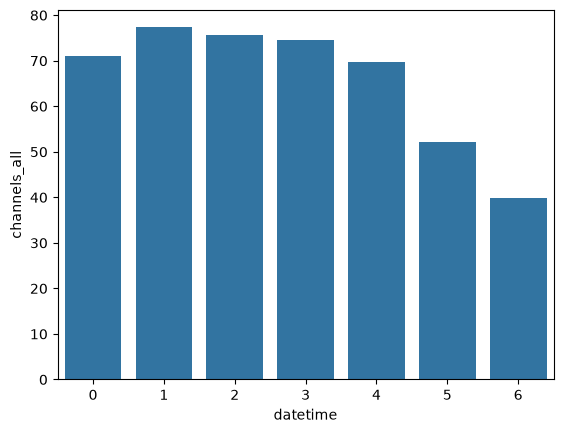

In [15]:
sns.barplot(df.groupby(by=df.datetime.dt.weekday).mean().channels_all)

<Axes: xlabel='datetime', ylabel='channels_all'>

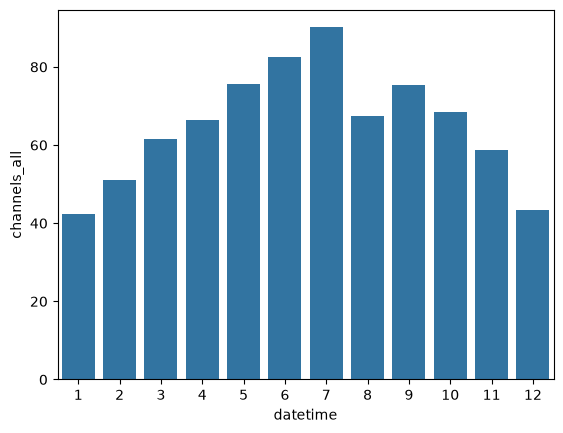

In [16]:
sns.barplot(df.groupby(by=df.datetime.dt.month).mean().channels_all)

In [ ]:
station_0 = df.loc[df.location_index == 0, "channels_all"]
station_0.index = df.loc[df.location_index == 0, "datetime"]
mean_0 = station_0.mean()
print(mean_0)

print(station_0.size)

188.9364289771058
51061


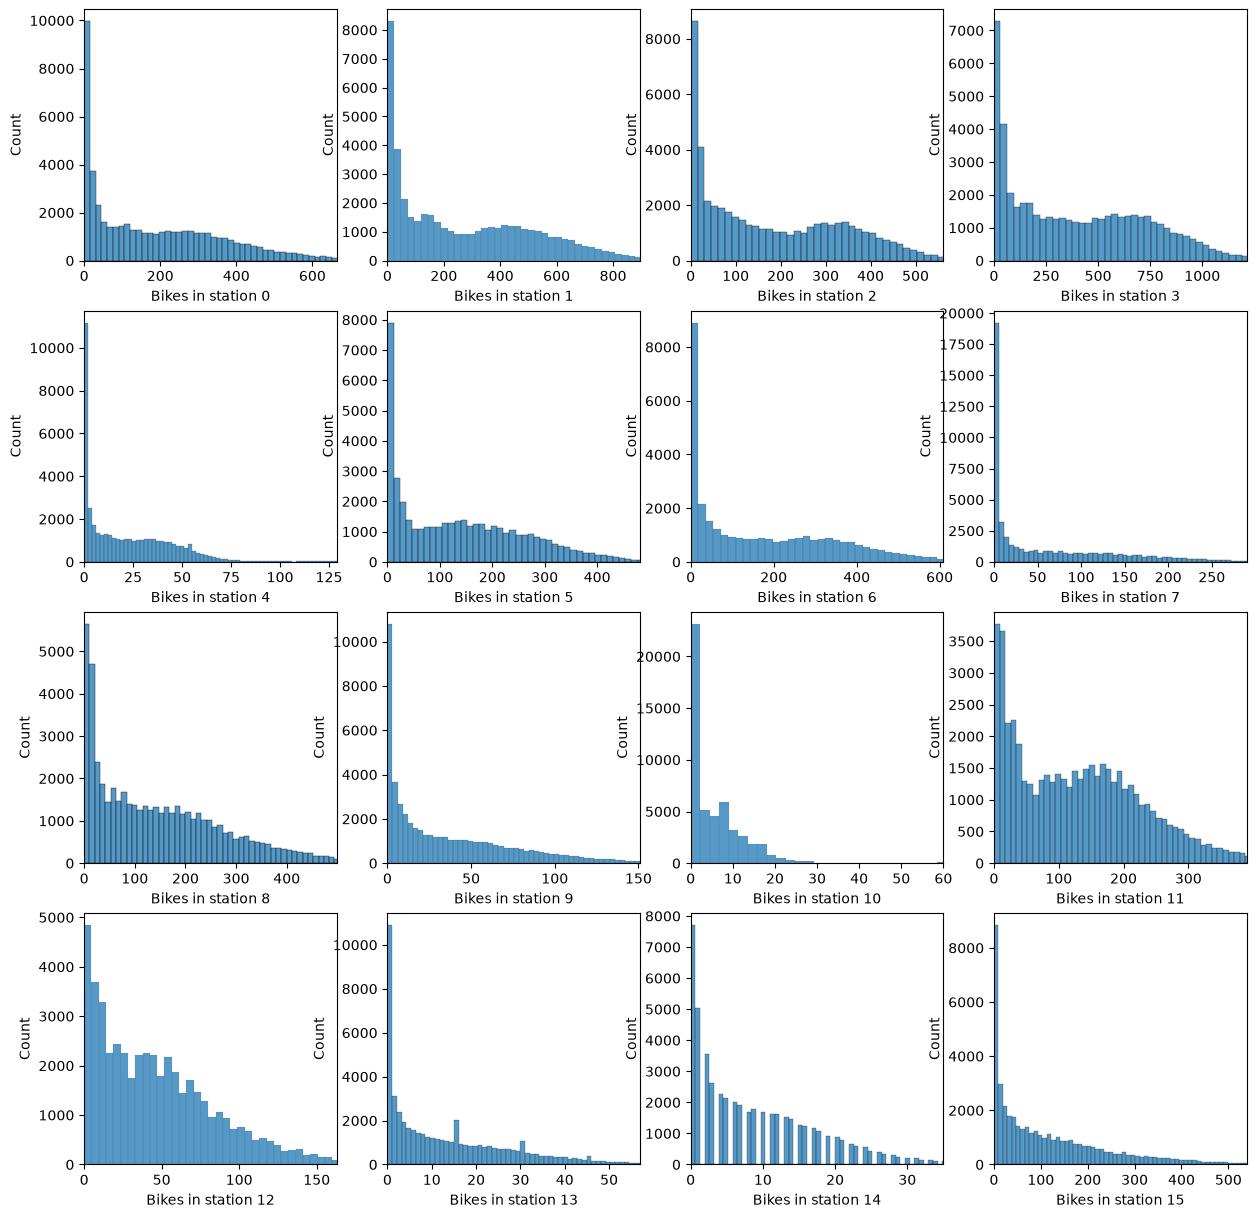

In [36]:
N = 4
fig, axs = plt.subplots(N, N, figsize=(15, 15))
for i in range(N*N):
    ax = axs.flatten()[i]
    station_channel = df.loc[df.location_index == i, "channels_all"]
    sns.histplot(df.loc[df.location_index == i, "channels_all"], ax=ax)
    ax.set_xlim(0, station_channel.quantile(0.99))
    ax.set_xlabel(f"Bikes in station {i}")

In [ ]:
nonzero_rain_mask = df.site_rain_accumulation > 0

fig, ax = plt.subplots()
sns.histplot(df.site_rain_accumulation, ax=ax)
ax.set_xlim(0, df.site_rain_accumulation.quantile(0.99))

KeyboardInterrupt: 